|   $B_{SQM}^{1/4}$   | $m_s$ |
|:-----:|:---:|
| 170   | 50  |
| 170   | 100 |
| 170   | 200 |
| 180   | 50  |
| 180   | 100 |
| 180   | 200 |
| 190   | 50  |
| 190   | 100 |
| 190   | 200 |

In [5]:
from RMFsolver.phase_velocity import vNtoQ
import RMFsolver.RMFparameter as para
import time

start = time.time()
ve = vNtoQ(
    T = 30,                    # temperature in MeV
    B_SQM = 170,              # Bag constant for quark matter bag model, in MeV
    DelP = 1e8,               # measures how far from equilibrium; this can't be determined from bag constant
    m_s = 50,                # strange quark mass
    param = para.paraQMCRMF3, # RMF model for nuclear matter
    NM_type = "PNM",          # nuclear matter type: pure neutron NM. other options: Beta_eq, SYM
    method = "analytical"
)
end = time.time()

ve

RuntimeError: aQstar = 0.6016120680380521 > aN = 0.5359084713361534

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

N = 25
meth = "numerical"
B_of = 180
m_strange = 100

TT = np.linspace(1, 30, N)
DD = np.linspace(1e+6, 1e+8, N)

V = np.zeros([N, N])

for i in range(N):  # loop over T (rows)
    for j in range(N):  # loop over B (columns)
        V[i, j] = vNtoQ(
            T = TT[i],
            B_SQM = B_of,
            DelP = DD[j],
            m_s = m_strange,
            param = para.paraQMCRMF3,
            NM_type = "PNM",
            method = meth
        )
        print(i, j)

np.save("DelP_T_B"+str(B_of)+"_ms"+str(m_strange)+"_"+meth+".npy", V)

Text(0, 0.5, 'T  (MeV)')

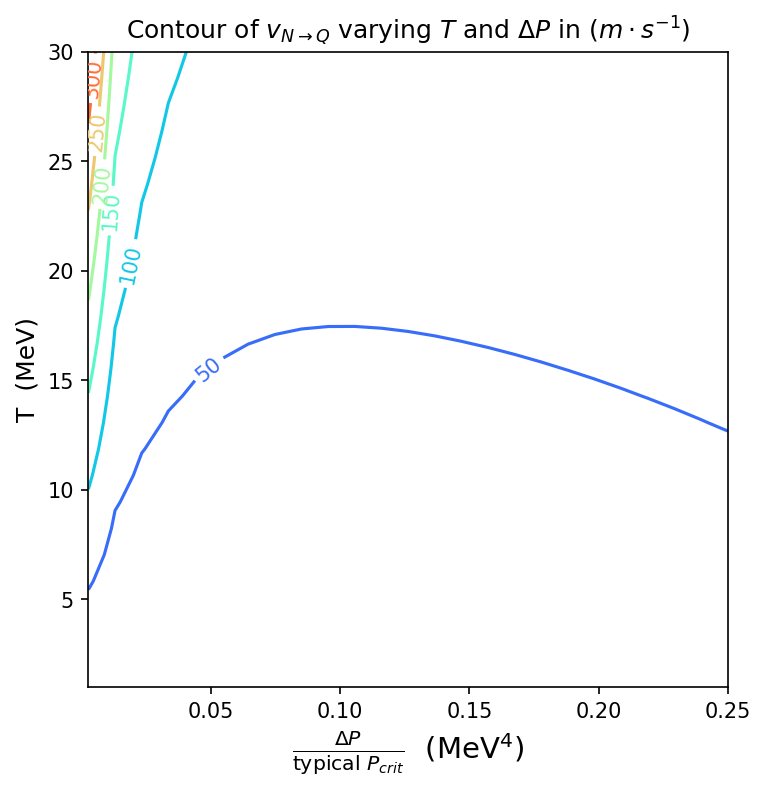

In [12]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=[5.5, 5.5])
plt.rcParams["figure.dpi"] = 150

# Plotting
#T_grid, D_grid = np.meshgrid(TT, DD)  # note BB first for x, TT for 

V = np.load("DelP_T_V.npy")
D_grid, T_grid = np.meshgrid(np.linspace(1e6, 1e8, 25)/4e8, np.linspace(1, 30, 25))

contours = plt.contour(D_grid, T_grid, V.T, cmap="rainbow")
plt.clabel(contours, inline=True, fontsize=10)

plt.title(r"Contour of $v_{N\to Q}$ varying $T$ and $\Delta P$ in $(m\cdot s^{-1})$")
plt.xlabel(r"$\frac{\Delta P}{\text{typical }P_{crit}}$  (MeV$^4$)", fontsize=14)
plt.ylabel("T  (MeV)", fontsize=12)

#plt.savefig("DelP_T_B"+str(B_of)+"_ms"+str(m_strange)+"_"+meth+".pdf", dpi=300)  # Increase DPI as needed

In [10]:
V.shape

(25, 25)

In [1]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares 
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import n_B, P_f, PQM

In [3]:
muB = 1000
muK = 30
B_one_forth = 180
T = 10
m_s = 100
upB = 5000

B = B_one_forth**4
mu_u = muB/3
mu_d = muB/3 + muK/2
mu_s = muB/3 - muK/2

n_u = n_B(mu_u, 0, T,)
n_d = n_B(mu_d, 0, T,)
n_s = n_B(mu_s, m_s, T,)

n_e = (2*n_u - n_d - n_s)/3
solve_for_mu_e = lambda x: n_B(x, 0, T,) - n_e
mu_e = fsolve(solve_for_mu_e, 100)[0]

if T > 0.5:
    Pres = float( 3*P_f(mu_u, m=0, Tem=T) + 3*P_f(mu_d, m=0, Tem=T) + 3*P_f(mu_s, m=m_s, Tem=T) - B )

else:
    Pres = float( ((mu_d)**4 + (mu_u)**4) * 3/(12*np.pi**2) + 3*P_f(mu_s, m_s, 0,) - B )

PQM(1000, 30, 180, 10, 100,)/Pres

0.9908852348556095

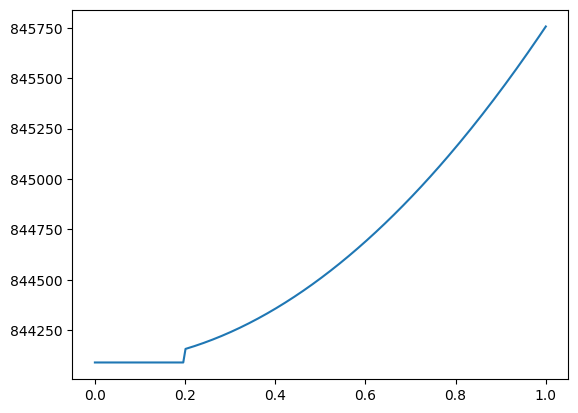

In [3]:
TT = np.linspace(0, 1, 200)

P = [P_f(mu=100, m=1, Tem=t,) for t in TT]

plt.plot(TT, P)


In [5]:
PQM(1000, 30, 180, 10, 0,)/PQM(1000, 30, 180, 10, 10,)

0.9920044778775813

In [1]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve
from scipy.optimize import approx_fprime
from scipy.optimize import root_scalar
from scipy.optimize import root
from scipy.optimize import least_squares
from numdifftools import Gradient
from numdifftools import Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu
from RMFsolver.Solver import RMFpressureSYM
from RMFsolver.Solver import RMFpressurePNM
from RMFsolver.Solver import pressure_RMF

from RMFsolver.phase_velocity import P_f, n_B, PQM, vNtoQ_Pc, vNtoQ_B

def PNM(mu_B, Temp, param=para.paraQMCRMF3, ):
    pre = RMFpressurePNM(
        input_num = mu_B,
        input_type = "muB", 
        Trmf = Temp, 
        para = param, 
        sigma_init = 30, 
        w0_init = 20, 
        r03_init = -3, 
        mub_init = 990,
        verb = False
        )
    return float(pre.item())

#### old

In [2]:
start = time.time()
ve2 = vNtoQ_Pc(
    T = 10,                    # temperature in MeV
    P_crit = 1e8,              # transition pressure in MeV^4
    DelP = 1e7,               # measures how far from equilibrium; this can't be determined from bag constant
    m_s = 50,                # strange quark mass
    param = para.paraQMCRMF3, # RMF model for nuclear matter
    NM_type = "PNM",          # nuclear matter type: pure neutron NM. other options: Beta_eq, SYM
    method = "analytical"
)
end = time.time()

ve2, end - start

((np.float64(22.155431509578065), np.float64(173.34422614425867)),
 8.217339992523193)

#### new

In [3]:
start = time.time()
ve2 = vNtoQ_Pc(
    T = 10,                    # temperature in MeV
    P_crit = 1e8,              # transition pressure in MeV^4
    DelP = 1e7,               # measures how far from equilibrium; this can't be determined from bag constant
    m_s = 50,                # strange quark mass
    param = para.paraQMCRMF3, # RMF model for nuclear matter
    NM_type = "PNM",          # nuclear matter type: pure neutron NM. other options: Beta_eq, SYM
    method = "numerical"
)
end = time.time()

ve2, end - start

((np.float64(22.532813053841075), np.float64(173.3282854766152)),
 15.652467966079712)

In [18]:
import numpy as np
import matplotlib.pyplot as plt

N = 25
meth = "numerical"
Pc = 1e8
m_strange = 0

TT = np.linspace(1, 65, N)
DD = np.linspace(1e+6, 4e+7, N)

V = np.zeros([N, N])

for i in range(N):  # loop over T (rows)
    for j in range(N):  # loop over B (columns)
        V[i, j] = vNtoQ_Pc(
            T = TT[i],
            P_crit = Pc,
            DelP = DD[j],
            m_s = m_strange,
            param = para.paraQMCRMF3,
            NM_type = "PNM",
            method = meth
        )
        print(i, j)

np.save("DelP_T_Pcrit="+format(Pc, '.0e').replace('+0', '').replace('+', '')+"_ms="+str(m_strange)+"_"+meth+".npy", V)

0 0
0 1
0 2
0 3
0 4
0 5
0 6
0 7
0 8
0 9
0 10
0 11
0 12
0 13
0 14
0 15
0 16
0 17
0 18
0 19
0 20
0 21
0 22
0 23
0 24
1 0
1 1
1 2
1 3
1 4
1 5
1 6
1 7
1 8
1 9
1 10
1 11
1 12
1 13
1 14
1 15
1 16
1 17
1 18
1 19
1 20
1 21
1 22
1 23
1 24
2 0
2 1
2 2
2 3
2 4
2 5
2 6
2 7
2 8
2 9
2 10
2 11
2 12
2 13
2 14
2 15
2 16
2 17
2 18
2 19
2 20
2 21
2 22
2 23
2 24
3 0
3 1
3 2
3 3
3 4
3 5
3 6
3 7
3 8
3 9
3 10
3 11
3 12
3 13
3 14
3 15
3 16
3 17
3 18
3 19
3 20
3 21
3 22
3 23
3 24
4 0
4 1
4 2
4 3
4 4
4 5
4 6
4 7
4 8
4 9
4 10
4 11
4 12
4 13
4 14
4 15
4 16
4 17
4 18
4 19
4 20
4 21
4 22
4 23
4 24
5 0
5 1
5 2
5 3
5 4
5 5
5 6
5 7
5 8
5 9
5 10
5 11
5 12
5 13
5 14
5 15
5 16
5 17
5 18
5 19
5 20
5 21
5 22
5 23
5 24
6 0
6 1
6 2
6 3
6 4
6 5
6 6
6 7
6 8
6 9
6 10
6 11
6 12
6 13
6 14
6 15
6 16
6 17
6 18
6 19
6 20
6 21
6 22
6 23
6 24
7 0
7 1
7 2
7 3
7 4
7 5
7 6
7 7
7 8
7 9
7 10
7 11
7 12
7 13
7 14
7 15
7 16
7 17
7 18
7 19
7 20
7 21
7 22
7 23
7 24
8 0
8 1
8 2
8 3
8 4
8 5
8 6
8 7
8 8
8 9
8 10
8 11
8 12
8 13
8 14
8 15
8 16
8 17


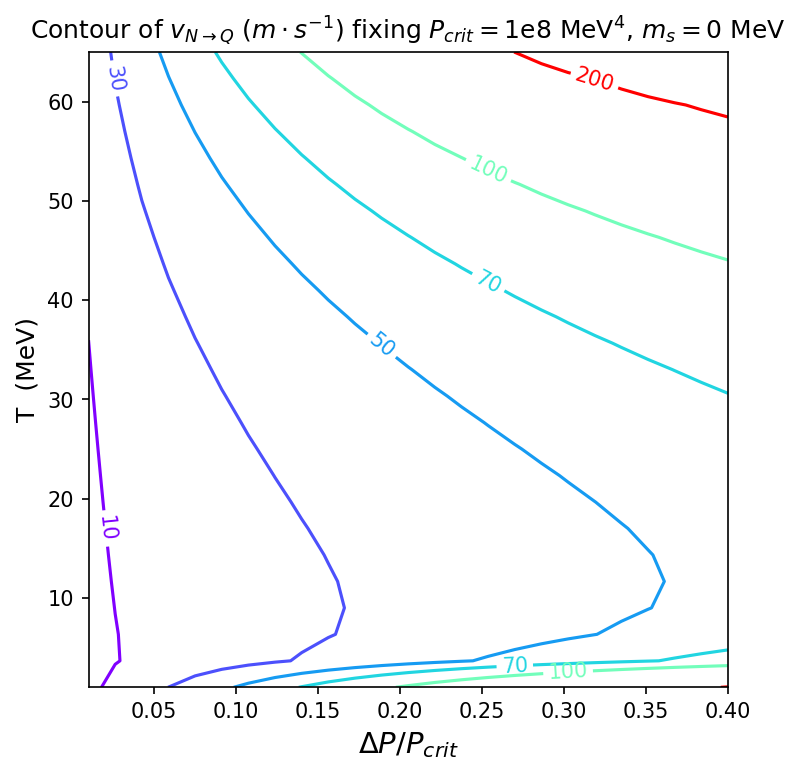

In [20]:
plt.figure(figsize=[5.5, 5.5])
plt.rcParams["figure.dpi"] = 150

# Plotting
T_grid, D_grid = np.meshgrid(TT, DD)  # note BB first for x, TT for 

#V_old = np.load("DelP_T_B180_ms100.npy")
#D_grid_old, T_grid_old = np.meshgrid(np.linspace(1e6, 1e8, N)/4e8, np.linspace(1, 30, N))

contours = plt.contour(D_grid/Pc, T_grid, V.T, levels = np.array([10, 30, 50, 70, 100, 200]), cmap="rainbow")
plt.clabel(contours, inline=True, fontsize=10)

plt.title(r"Contour of $v_{N\to Q}$ ($m\cdot s^{-1}$) fixing $P_{crit}=$"+format(Pc, '.0e').replace('+0', '').replace('+', '')+r" MeV$^4$, $m_s=$"+str(m_strange)+" MeV" )
plt.xlabel(r"$\Delta P / P_{crit}$", fontsize=14)
plt.ylabel("T  (MeV)", fontsize=12)

plt.savefig("DelP_T_Pcrit="+format(Pc, '.0e').replace('+0', '').replace('+', '')+"_ms="+str(m_strange)+"_"+meth+".pdf", dpi=300)  # Increase DPI as needed

In [11]:
start = time.time()
ve2 = vNtoQ_Pc(
    T = 5,                    # temperature in MeV
    P_crit = 3e8,              # transition pressure in MeV^4
    DelP = 1e7,               # measures how far from equilibrium; this can't be determined from bag constant
    m_s = 90,                # strange quark mass
    param = para.paraQMCRMF3, # RMF model for nuclear matter
    NM_type = "PNM",          # nuclear matter type: pure neutron NM. other options: Beta_eq, SYM
    method = "numerical"
)
end = time.time()

ve2, end - start

((np.float64(16.559967415378384), np.float64(177.51362063266743)),
 17.55095601081848)

In [42]:
import numpy as np
import matplotlib.pyplot as plt

N = 25
meth = "numerical"
Te = 20
DeltaP = 5e7

PPc = np.linspace(1e8, 2e8, N)
MM = np.linspace(10, 200, N)

V = np.zeros([N, N])

for i in range(N):  # loop over T (rows)
    for j in range(N):  # loop over B (columns)
        V[i, j] = vNtoQ_Pc(
            T = Te,
            P_crit = PPc[i],
            DelP = DeltaP,
            m_s = MM[j],
            param = para.paraQMCRMF3,
            NM_type = "PNM",
            method = meth
        )
        print(i, j)

np.save("MS_Pc_DelP="+format(DeltaP, '.0e').replace('+0', '').replace('+', '')+"_T="+str(Te)+"_"+meth+".npy", V)

0 0
0 1
0 2
0 3
0 4
0 5
0 6
0 7
0 8
0 9
0 10
0 11
0 12
0 13
0 14
0 15
0 16
0 17
0 18
0 19
0 20
0 21
0 22
0 23
0 24
1 0
1 1
1 2
1 3
1 4
1 5
1 6
1 7
1 8
1 9
1 10
1 11
1 12
1 13
1 14
1 15
1 16
1 17
1 18
1 19
1 20
1 21
1 22
1 23
1 24
2 0
2 1
2 2
2 3
2 4
2 5
2 6
2 7
2 8
2 9
2 10
2 11
2 12
2 13
2 14
2 15
2 16
2 17
2 18
2 19
2 20
2 21
2 22
2 23
2 24
3 0
3 1
3 2
3 3
3 4
3 5
3 6
3 7
3 8
3 9
3 10
3 11
3 12
3 13
3 14
3 15
3 16
3 17
3 18
3 19
3 20
3 21
3 22
3 23
3 24
4 0
4 1
4 2
4 3
4 4
4 5
4 6
4 7
4 8
4 9
4 10
4 11
4 12
4 13
4 14
4 15
4 16
4 17
4 18
4 19
4 20
4 21
4 22
4 23
4 24
5 0
5 1
5 2
5 3
5 4
5 5
5 6
5 7
5 8
5 9
5 10
5 11
5 12
5 13
5 14
5 15
5 16
5 17
5 18
5 19
5 20
5 21
5 22
5 23
5 24
6 0
6 1
6 2
6 3
6 4
6 5
6 6
6 7
6 8
6 9
6 10
6 11
6 12
6 13
6 14
6 15
6 16
6 17
6 18
6 19
6 20
6 21
6 22
6 23
6 24
7 0
7 1
7 2
7 3
7 4
7 5
7 6
7 7
7 8
7 9
7 10
7 11
7 12
7 13
7 14
7 15
7 16
7 17
7 18
7 19
7 20
7 21
7 22
7 23
7 24
8 0
8 1
8 2
8 3
8 4
8 5
8 6
8 7
8 8
8 9
8 10
8 11
8 12
8 13
8 14
8 15
8 16
8 17


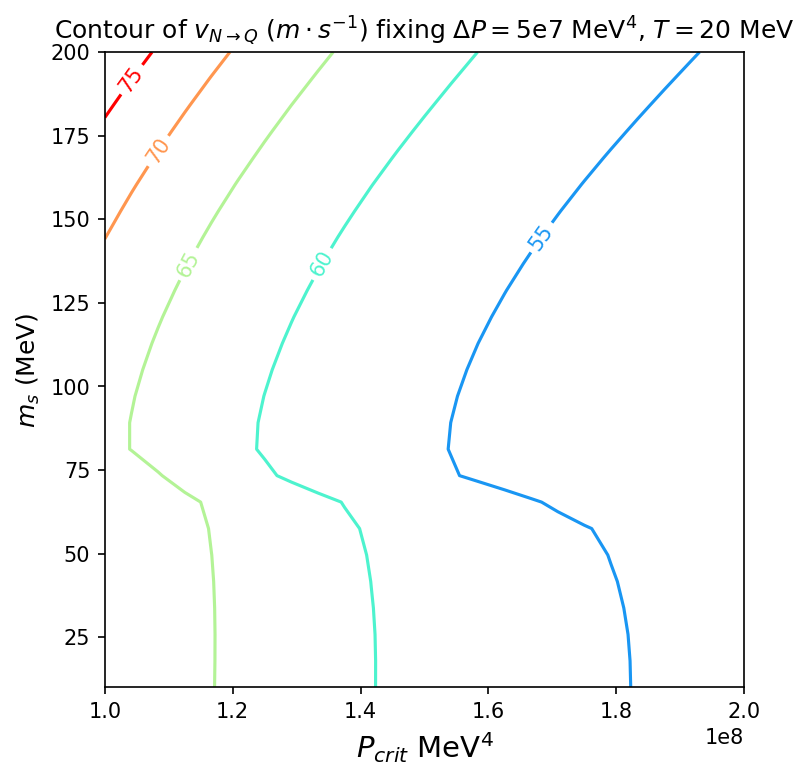

In [45]:
plt.figure(figsize=[5.5, 5.5])
plt.rcParams["figure.dpi"] = 150

# Plotting
M_grid, P_grid = np.meshgrid(MM, PPc)  # note BB first for x, TT for 

#V_old = np.load("DelP_T_B180_ms100.npy")
#D_grid_old, T_grid_old = np.meshgrid(np.linspace(1e6, 1e8, N)/4e8, np.linspace(1, 30, N))

contours = plt.contour(P_grid, M_grid, V, levels = np.array([50, 55, 60, 65, 70, 75]), cmap="rainbow")
plt.clabel(contours, inline=True, fontsize=10)

plt.title(r"Contour of $v_{N\to Q}$ ($m\cdot s^{-1}$) fixing $\Delta P=$"+format(DeltaP, '.0e').replace('+0', '').replace('+', '')+r" MeV$^4$, $T=$"+str(Te)+" MeV" )
plt.xlabel(r"$P_{crit}$ MeV$^4$", fontsize=14)
plt.ylabel(r"$m_s$ (MeV)", fontsize=12)

plt.savefig("MS_Pc_DelP="+format(DeltaP, '.0e').replace('+0', '').replace('+', '')+"_T="+str(Te)+"_"+meth+".pdf", dpi=300)  # Increase DPI as needed

In [44]:
V.max(), V.min()

(np.float64(78.74647215497637), np.float64(50.41832535517477))

In [10]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve
from scipy.optimize import approx_fprime
from scipy.optimize import root_scalar
from scipy.optimize import root
from scipy.optimize import least_squares
from numdifftools import Gradient
from numdifftools import Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFsolvePNM_mu
from RMFsolver.Solver import RMFpressureSYM
from RMFsolver.Solver import RMFpressurePNM
from RMFsolver.Solver import pressure_RMF

from RMFsolver.phase_velocity import P_f, n_B, PQM, vNtoQ_Pc, vNtoQ_B

In [9]:
RMFsolvePNM_mu(
    mub = 1100, 
    Trmf = 20, 
    para = para.paraQMCRMF3, 
    sigma_init = 30,
    w0_init = 20,
    r03_init = -3, 
)

[[np.float64(57.678698703191664),
  np.float64(44.89998222289187),
  np.float64(-4.723770819430966),
  1100,
  0.0,
  0.0],
 [np.float64(2.333894371986389e-05),
  np.float64(1.6398727893829346e-05),
  np.float64(-0.00010202638804912567),
  0,
  0],
 20,
 2963212.8086487385,
 [[939, 939],
  [491.5, 782.5, 763.0],
  [-0.5, 0.5],
  [8.32, 8.32],
  [9.76, 9.76],
  [11.02, 11.02],
  [0.0063, -0.006, 939],
  [0],
  [0],
  [5.87, 0, 0, 0, 0, 0, 0, 0, 0],
  1205350.8748737855,
  -1,
  -707480]]

In [12]:
15/12, (70 - 15)/18

(1.25, 3.0555555555555554)

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


In [14]:
from sympy import symbols, solve

x = symbols('x')
expr = (x - 9)/6 + x/12 + x/24 + (x - 15)/10

solution = solve(expr, x)
solution

[360/47]

In [16]:
x = 360 / 47
x

7.659574468085107

In [25]:
i1 = (9 - x)/6
i4 = (15 - x)/10
i2 = x/12
i3 = x/24

i1, i2, i3, i4

(0.22340425531914887,
 0.6382978723404256,
 0.3191489361702128,
 0.7340425531914894)

In [24]:
i2 - i1, i4 - i3

(0.4148936170212767, 0.4148936170212766)

In [26]:
s3 = np.sqrt(3)

s3 / (1 + s3), (1 - 1/s3)

(np.float64(0.6339745962155613), np.float64(0.42264973081037416))

In [1]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, n_B, vNtoQ_nc, vNtoQ_B, PQM

n0 = 0.16 * const.MeV_fm**3

In [2]:
import numpy as np
import matplotlib.pyplot as plt

N = 30
meth = "numerical"
nc = 4*n0
m_strange = 0

TT = np.hstack([np.linspace(1, 20, int(N*2/5)),np.linspace(20.5, 75, int(N*3/5))])
DD = np.linspace(0.01*nc, 0.1*nc, N)

V = np.zeros([N, N])

for i in range(N):  # loop over T (rows)
    for j in range(N):  # loop over B (columns)
        V[i, j] = vNtoQ_nc(
            T = TT[i],
            n_crit = nc,
            Deln = DD[j],
            m_s = m_strange,
            param = para.paraQMCRMF3,
            NM_type = "PNM",
            method = meth
        )
        print(i, j, V[i,j])

np.save("Deln_T_ncrit="+str(nc/n0)+".npy", V)

0 0 152.59117900297656
0 1 205.4549448093121
0 2 260.93722151609825
0 3 319.15988462518516
0 4 380.1732063881919
0 5 444.08533161982655
0 6 511.1196382310593
0 7 581.4022578755129
0 8 655.1119745495115
0 9 732.7127685448954
0 10 814.3292636400615
0 11 900.3403720159845
0 12 991.4503585276309
0 13 1087.8939026450907
0 14 1190.449188097962
0 15 1299.7177120781525
0 16 1416.7761268791467
0 17 1542.6497153606506
0 18 1678.5820249175406
0 19 1826.3308066304398
0 20 1987.8774725365438
0 21 2166.1706131151163
0 22 2364.4469552086853
0 23 2588.2654494315307
0 24 2842.784513623938
0 25 3138.648028395627
0 26 3489.574298548597
0 27 3917.5609795620594
0 28 4459.314975966315
0 29 5185.26620127806
1 0 70.41478693150279
1 1 92.9204564351634
1 2 116.48505404303492
1 3 141.17603946532006
1 4 167.05605323358782
1 5 194.12779319781035
1 6 222.4832985247435
1 7 252.26180482930334
1 8 283.4640309324849
1 9 316.2687368972648
1 10 350.8513711069351
1 11 387.27639335358316
1 12 425.8031676834722
1 13 466.614

/Users/janshao/NSM_related/RMFsolver/Solver.py:620: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  result, _ = quad(integrand, 0, upB, epsabs=1e-10, epsrel=1e-8)
/Users/janshao/NSM_related/RMFsolver/Solver.py:620: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the int

3 11 210.25219904277353
3 12 229.88943971293338
3 13 250.71013153703268
3 14 272.821027491733
3 15 296.4214144668203
3 16 321.6998075362388
3 17 348.84542303271473
3 18 378.2307742295932
3 19 410.20090668523386
3 20 445.2236500558942
3 21 483.83198487287905
3 22 526.9420915720568
3 23 575.5516844033265
3 24 631.1091724006525
3 25 695.7302920498353
3 26 772.7108555948078
3 27 867.0101582743507
3 28 987.0891138458354
3 29 1149.3903981566193
4 0 43.77018354904292
4 1 54.24754391860554
4 2 64.92534903734871
4 3 75.88961919939037
4 4 87.23329619667916
4 5 98.99157436006962
4 6 111.24157208865955
4 7 124.01124625089673
4 8 137.36600041822388
4 9 151.3672212668044
4 10 166.06965640057845


/Users/janshao/NSM_related/RMFsolver/Solver.py:620: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  result, _ = quad(integrand, 0, upB, epsabs=1e-10, epsrel=1e-8)
/Users/janshao/NSM_related/RMFsolver/Solver.py:620: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the int

4 11 181.5399619530735
4 12 197.88685138934002
4 13 215.21572978423018
4 14 233.61476348152516
4 15 253.23315276829823
4 16 274.22886535876887
4 17 296.8727886913009
4 18 321.3043919436469
4 19 347.91249668458175
4 20 377.04315328384274
4 21 409.2670488694704
4 22 445.1949277407995
4 23 485.7842832125082
4 24 532.2302757008459
4 25 586.4133614456848
4 26 650.9596794242744
4 27 730.2793184244557
4 28 831.7555401216654
4 29 969.5066640942707
5 0 42.43191023105354
5 1 52.00566880402405
5 2 61.64498613050537
5 3 71.47986762285004
5 4 81.58324961965769
5 5 92.01388000136282
5 6 102.82460908502085
5 7 114.0770219533351
5 8 125.81478342901637
5 9 138.09951348448598
5 10 150.97749189396288


/Users/janshao/NSM_related/RMFsolver/Solver.py:620: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  result, _ = quad(integrand, 0, upB, epsabs=1e-10, epsrel=1e-8)
/Users/janshao/NSM_related/RMFsolver/Solver.py:620: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the int

5 11 164.54011191269086
5 12 178.82576482231667
5 13 193.97363326738508
5 14 210.03659831971729
5 15 227.1758941219752
5 16 245.5496031120455
5 17 265.2740174932844
5 18 286.64308955956545
5 19 309.9208417138464
5 20 335.4188381340963
5 21 363.63051550688397
5 22 395.13049649438824
5 23 430.76235930341977
5 24 471.57885751175405
5 25 519.2888957519484
5 26 576.3713194592654
5 27 646.5438280434033
5 28 736.9134013522752
5 29 860.482941296495
6 0 41.81037745500407
6 1 50.8410885602854
6 2 59.84838356841323
6 3 68.96917581453656
6 4 78.2907272546095
6 5 87.86774483502786
6 6 97.76147704505954
6 7 108.02499001037683
6 8 118.70300425383526
6 9 129.85951283809467
6 10 141.54154247853108
6 11 153.82021353258017
6 12 166.76175635212527
6 13 180.45164551429596
6 14 194.9821694864866
6 15 210.48399457553873
6 16 227.07565891713048
6 17 244.92703468068706
6 18 264.23781412632985
6 19 285.2862157045671
6 20 308.37901235241486
6 21 333.93680959256335
6 22 362.5048025303435
6 23 394.8616827356555
6 

Text(0, 0.5, 'T  (MeV)')

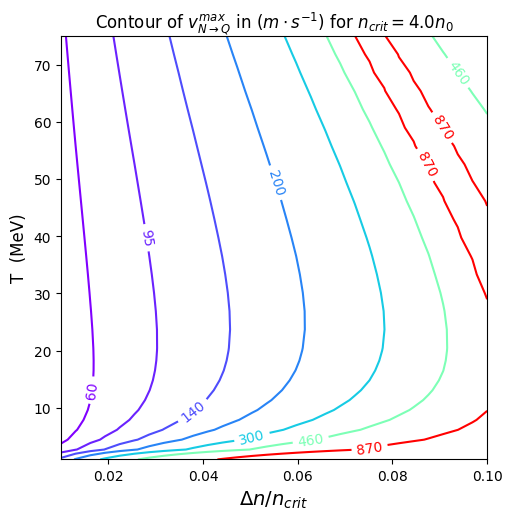

In [3]:
plt.figure(figsize=[5.5, 5.5])
plt.rcParams["figure.dpi"] = 150

# Plotting
T_grid, D_grid = np.meshgrid(TT, DD)  # note BB first for x, TT for 

#V_old = np.load("DelP_T_B180_ms100.npy")
#D_grid_old, T_grid_old = np.meshgrid(np.linspace(1e6, 1e8, N)/4e8, np.linspace(1, 30, N))

contours = plt.contour(D_grid/nc, T_grid, V.T, levels = np.array([60, 95, 140, 200, 300, 460, 870]), cmap="rainbow")
plt.clabel(contours, inline=True, fontsize=10)

plt.title(r"Contour of $v_{N\to Q}^{max}$ in ($m\cdot s^{-1}$) for $n_{crit}=$"+str(nc/n0)+r"$n_0$" )
plt.xlabel(r"$\Delta n / n_{crit}$", fontsize=14)
plt.ylabel("T  (MeV)", fontsize=12)

#plt.savefig("Deln_T_ncrit="+str(nc/n0)+".pdf", dpi=300)  # Increase DPI as needed

In [3]:
V.max(), V.min()

(np.float64(541.8867152076896), np.float64(9.973806528437137))

In [2]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, n_B, vNtoQ_nc, vNtoQ_B, PQM, _find_muB_muK_star

n0 = 0.16 * const.MeV_fm**3

def Get_Two_as(T, n_crit, Deln, m_s, param, NM_type, method):
    '''
    Computes NM to SQM phase boundary velocity 

    Parameters:
    - T        : temperature
    - n_crit   : critical density for 1st order phase transition
    - Deln     : Messures how far away from equilibrium
    - m_s      : strange quark mass
    - param    : mean field theory model settings for nuclear matter
    - NM_type  : assumptions for nuclear matter, choose from:
                 - "Beta_eq" for beta equilibriated nuclear matter
                 - "PNM" for pure neutron matter
                 - "SYM" for symmetric nuclear matter
    - method   : ways to calculate velocity
                 - "numerical" in principle more precise, but have numerical noise
                 - "analytical" analytical approximation, direct, faster, and robust, ~ 10% difference with numerical method

    Returns:
    - velocity of phase boundary in meters per second
    '''

    def PNM(mu_B, Temp):
        if NM_type == "Beta_eq":
            rmf_sol = RMFsolve_mu(mub = mu_B, Trmf = Temp, para = param, 
                sigma_init = 30, w0_init = 20, r03_init = -3, mu_e_init = 50, verb = False
                )
            return (pressure_RMF(rmf_sol)).item()

        elif NM_type == "PNM":
            pre = RMFpressurePNM(input_num = mu_B, input_type = "muB", Trmf = Temp, para = param, 
                sigma_init = 30, w0_init = 20, r03_init = -3, mub_init = 990, verb = False
                )
            return float(pre.item())

        elif NM_type == "SYM":
            pre = RMFpressureSYM(input_num = mu_B, input_type = "muB", Trmf = Temp, para = param, 
                sigma_init = 30, w0_init = 20, mub_init = 990, verb = False
                )
            return float(pre.item())

        else:
            return ValueError("Nuclear matter type not defined.")


    def PNM_n(nB, Temp):
        if NM_type == "Beta_eq":
            rmf_sol = RMFsolve(nbext = nB, Trmf = Temp, para = param, 
                sigma_init = 30, w0_init = 20, r03_init = -3, mu_e_init = 50, verb = False
                )
            return (pressure_RMF(rmf_sol)).item()

        elif NM_type == "PNM":
            pre = RMFpressurePNM(input_num = nB, input_type = "nB", Trmf = Temp, para = param, 
                sigma_init = 30, w0_init = 20, r03_init = -3, mub_init = 990, verb = False
                )
            return float(pre.item())

        elif NM_type == "SYM":
            pre = RMFpressureSYM(input_num = nB, input_type = "nB", Trmf = Temp, para = param, 
                sigma_init = 30, w0_init = 20, mub_init = 990, verb = False
                )
            return float(pre.item())

        else:
            return ValueError("Nuclear matter type not defined.")
  

    # solve for bag constant
    P_crit = PNM_n(n_crit, T)
    P_diff = lambda x: PNM(x, T) - P_crit
    muB_crit = fsolve(P_diff, 1050)[0]
    PQM_solve_for_B = lambda x: PQM(muB_crit, 0, x, T, m_s) - P_crit
    B_SQM = fsolve(PQM_solve_for_B, 180)[0]

    # solve for points Q and N at beta eq.
    DelP = PNM_n(n_crit + Deln, T) - P_crit
    PNM_minus_PShift = lambda x: PNM(x,T) - P_crit - DelP
    muB_N = fsolve(PNM_minus_PShift, 1050)[0]

    PQM_minus_Pshift = lambda x: PQM(x, 0, B_SQM, T, m_s) - P_crit - DelP
    muB_Q = fsolve(PQM_minus_Pshift, 1050)[0]

    # calculating aQstar
    if method == "numerical":
        epsilon = np.sqrt(np.finfo(float).eps)
        muB_star, muK_star = _find_muB_muK_star(PQM, P_crit + DelP, muB_N, B_SQM, T, m_s)
        PQM_wrap = lambda Mu: PQM(Mu[0], Mu[1], B_SQM, T, m_s)
        grad_Qstar = approx_fprime(np.array([muB_star, muK_star]), PQM_wrap, epsilon)
        nB_Qstar = grad_Qstar[0]
        nK_Qstar = grad_Qstar[1]
        grad_Q = approx_fprime(np.array([muB_Q, 0]), PQM_wrap, epsilon)
        nB_Q = grad_Q[0]
        nK_Q = grad_Q[1]
        aQstar = (nK_Qstar - nK_Q)/nB_Q  
 
    elif method == "analytical":
        PQM_muB = lambda Mu: PQM(Mu, 0, B_SQM, T, m_s)
        PQM_muK = lambda Mu: PQM(muB_Q, Mu, B_SQM, T, m_s)
        ddPQM_ddmuK = Derivative(PQM_muK, n=2)
        dPQM_dmuK = Derivative(PQM_muK, n=1)
        dPQM_dmuB = Derivative(PQM_muB, n=1)
        chiK_Q = ddPQM_ddmuK(0)
        nB_Q = dPQM_dmuB(muB_Q)
        nK_Q = dPQM_dmuK(0)
        aQstar = np.sqrt(2*(muB_N - muB_Q)*chiK_Q / nB_Q)
        muK_star = np.sqrt(2 * nB_Q * (muB_N - muB_Q) / chiK_Q)
        PQM_solve_for_muBstar = lambda x: PQM(x, muK_star, B_SQM, T, m_s) - P_crit
        muB_star = fsolve(PQM_solve_for_muBstar, muB_Q)[0]

    else:
        raise RuntimeError(f"Input method unknown")
        return None

    # calculating aN
    PNM_wrap = lambda x: PNM(x, T)
    dPNM_dmuB = Derivative(PNM_wrap, n=1)
    nB_N = dPNM_dmuB(muB_N)
    aN = (nB_N - nK_Q) / nB_Q   

    return aQstar, aN

In [5]:
import numpy as np
import time
from tqdm import tqdm
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, n_B, vNtoQ_nc, Get_Two_as_dens, PQM, _find_muB_muK_star

n0 = 0.16 * const.MeV_fm**3

N = 30
nc = 4*n0
m_strange = 0

TT = np.logspace(np.log10(0.01), np.log10(100), N) #np.hstack([np.linspace(1, 20, int(N*2/5)),np.linspace(20.5, 72, int(N*3/5))])
DD = np.linspace(0.01*n0, 0.5*n0, N)

a_diff = np.zeros([N, N])

for i in tqdm(range(N), desc="Computing for 4 n0"):  # loop over T (rows)
    for j in range(N):  # loop over B (columns)
        aQ_tmp, aN_tmp = Get_Two_as_dens(
            T = TT[i],
            n_crit = nc,
            Deln = DD[j],
            m_s = m_strange,
            param = para.paraQMCRMF3,
            NM_type = "PNM",
        )
        a_diff[i,j] = aN_tmp - aQ_tmp
        #print(i, j, a_diff[i,j])

#np.save("aQstar_aN_n_crit="+str(nc/n0)+".npy", a_diff)

Computing for 4 n0: 100%|████████████████████| 30/30 [1:51:41<00:00, 223.40s/it]


Text(0, 0.5, 'T  (MeV)')

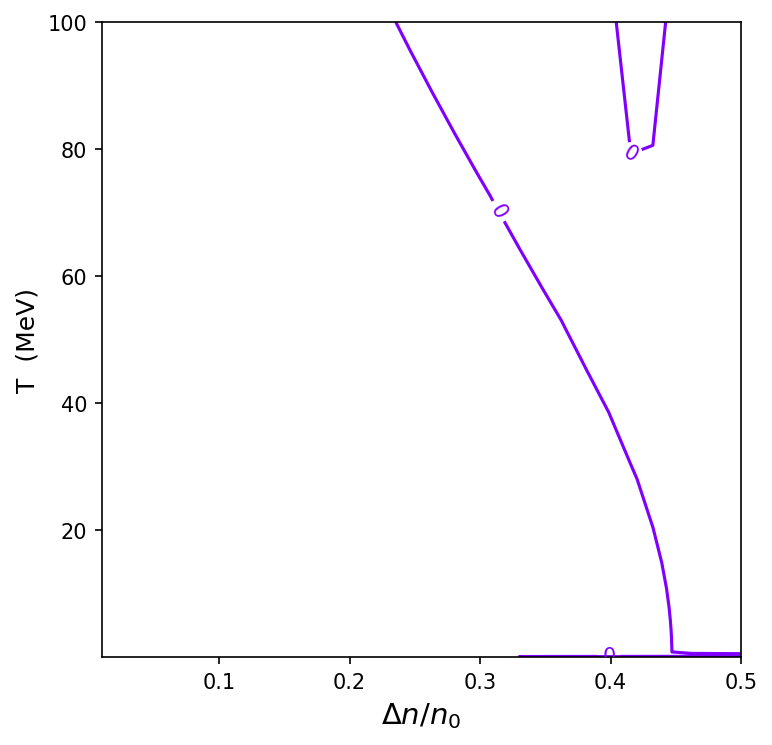

In [8]:
T_grid, D_grid = np.meshgrid(TT, DD)

plt.figure(figsize=[5.5, 5.5])
plt.rcParams["figure.dpi"] = 150

# Plotting


#V_old = np.load("DelP_T_B180_ms100.npy")
#D_grid_old, T_grid_old = np.meshgrid(np.linspace(1e6, 1e8, N)/4e8, np.linspace(1, 30, N))

contours = plt.contour(D_grid/n0, T_grid, a_diff.T, levels = [0], cmap="rainbow")
plt.clabel(contours, inline=True, fontsize=10)

#plt.title(r"Contour of $v_{N\to Q}^{max}$ in ($m\cdot s^{-1}$) for $n_{crit}=$"+str(nc/n0)+r"$n_0$" )
plt.xlabel(r"$\Delta n / n_{0}$", fontsize=14)
plt.ylabel("T  (MeV)", fontsize=12)
#plt.yscale('log')

#plt.savefig("Deln_T_ncrit="+str(nc/n0)+".pdf", dpi=300)  # Increase DPI as needed

0.3407951210211752


(1.0, 72.0)

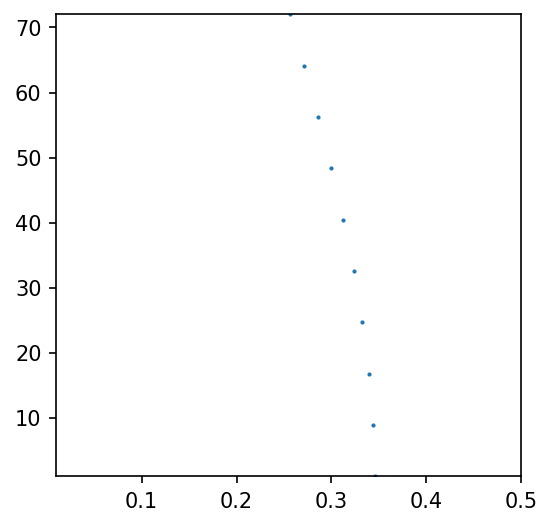

In [8]:
import numpy as np
from scipy.interpolate import interp1d

from RMFsolver.phase_velocity import extract_contour_coords_num
Deln_cut, T_cut = extract_contour_coords_num(D_grid, T_grid, a_diff.T, level=0)

# Suppose your arrays are:
# Deln_cut = np.array([...])   # x values
# T_cut = np.array([...])      # y values

# Define interpolation function: x = f(y)
Cut = interp1d(T_cut, Deln_cut, kind='linear', fill_value="extrapolate")

print(Cut(15)/n0)

# Example usage:
Tempr = np.linspace(1, 72, 10)
Del = np.array([Cut(Tempr[i]) for i in range(len(Tempr))])

plt.figure(figsize=[4,4])
plt.scatter(Del/n0, Tempr, s=1)
plt.xlim(0.01, 0.5)
plt.ylim(1, 72)

In [21]:
#np.save("Shade_n_crit="+str(nc/n0)+".npy", np.array([Deln_cut, T_cut]))

In [9]:
import numpy as np
import matplotlib.pyplot as plt

N = 30
meth = "numerical"
nc = 4.5*n0
m_strange = 0

TT = np.hstack([np.linspace(1, 20, int(N*2/5)),np.linspace(20.5, 72, int(N*3/5))])
#DD = np.linspace(0.01*n0, 0.5*n0, N)

V = np.zeros([N, N])

for i in range(N):  # loop over T (rows)
    DD = np.linspace(0.01*n0, np.minimum(0.5*n0, Cut(TT[i])-0.015*n0), N)
    for j in range(N):  # loop over B (columns)
        V[i,j], _ = vNtoQ_nc(
            T = TT[i],
            n_crit = nc,
            Deln = DD[j],
            m_s = m_strange,
            param = para.paraQMCRMF3,
            NM_type = "PNM",
            method = meth
        )
        print(i, j, V[i,j])

np.save("v_n_crit="+str(nc/n0)+".npy", V)

0 0 51.48763256918007
0 1 110.77440818789314
0 2 174.15819398234578
0 3 241.44851744251662
0 4 312.5612761254031
0 5 387.69910065878923
0 6 466.9470943732473
0 7 550.5436826376194
0 8 638.9686517740613
0 9 732.4460974185336
0 10 831.3437981811046
0 11 936.4315225352709
0 12 1048.3346824243213
0 13 1167.8864211886166
0 14 1296.0147961542766
0 15 1433.9622180762037
0 16 1583.2167715087912
0 17 1745.6212388797703
0 18 1923.6226891185522
0 19 2120.2152308008313
0 20 2339.853132340573
0 21 2588.146995754734
0 22 2872.5032718792495
0 23 3204.4594784756086
0 24 3602.2543423010143
0 25 4092.058235929069
0 26 4724.850488496451
0 27 5596.198497274394
0 28 6934.058778820567
0 29 9481.221721644088
1 0 27.664939667171947
1 1 53.423465403306245
1 2 80.55316668922424
1 3 109.1943699591654
1 4 139.41152442740474
1 5 171.2622892676968
1 6 204.85035771959977
1 7 240.3154211843179
1 8 277.729247952418
1 9 317.26172677825775
1 10 359.1762853199242
1 11 403.6452332953993
1 12 451.0106040811657
1 13 501.612

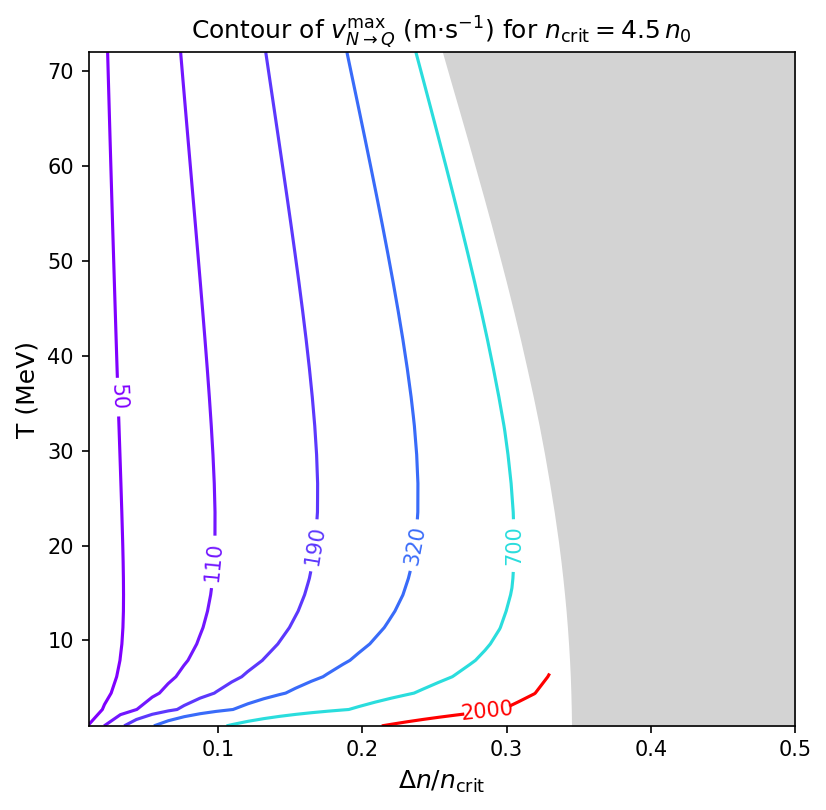

In [20]:
#np.array([25, 40, 55, 70, 90, 115, 150, 200])
# Inputs you already have:
# TT: (N,) temperatures
# V : (N, N) values with V[i, j] corresponding to (TT[i], DD[i, j])
# n0, nc, Cut: given in your code
N = len(TT)

# --- build the irregular structured grid ---
# along-row parameter (0..1) for each density sample
t = np.linspace(0.0, 1.0, N)

# upper bound for Δn at each TT[i]
Dmax = np.minimum(0.5 * n0, Cut(TT) - 0.015 * n0)           # shape (N,)

# ensure the upper bound is at least the lower bound to avoid inverted/degenerate rows
Dlo  = 0.01 * n0
Dmax = np.maximum(Dmax, Dlo)

# density grid: for each i, linspace(Dlo, Dmax[i], N)
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]            # shape (N, N)

# temperature grid: each row equals TT[i]
T_grid = np.repeat(TT[:, None], N, axis=1)                   # shape (N, N)

# If V was stored transposed, fix it here so V[i,j] matches (T_grid[i,j], D_grid[i,j]).
Z = V.T if V.shape != D_grid.shape else V

# --- plot ---
plt.figure(figsize=(5.5, 5.5), dpi=150)

levels = np.array([50, 110, 190, 320, 700, 2000])
cs = plt.contour(D_grid / n0, T_grid, Z, levels=levels, cmap="rainbow")
plt.clabel(cs, inline=True, fontsize=10)

plt.title(r"Contour of $v_{N\to Q}^{\max}$ (m·s$^{-1}$) for $n_{\rm crit}=$"
          + f"{nc/n0:.3g}" + r"$\,n_0$")
plt.xlabel(r"$\Delta n / n_{\rm crit}$", fontsize=12)
plt.ylabel("T (MeV)", fontsize=12)
plt.tight_layout()

Dcut = Cut(TT)                    # shape (N,)
Dhi  = 0.5 * n0 * np.ones_like(TT)

# fill between Dcut and 0.5 n0, normalized by nc
plt.fill_betweenx(
    TT,                           # y-axis = temperatures
    Dcut / n0,                    # left boundary
    Dhi  / n0,                    # right boundary
    color="lightgrey", alpha=1, label="Excluded region"
)

plt.xlim(0.01, 0.5)
plt.ylim(1,72)

plt.show()

In [1]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, vNtoQ_Pc, vNtoQ_B, vNtoQ_nc, PQM, PQM_em, Get_Delta_n_max, _find_muB_muK_star

def PNM(mu_B, Temp, param=para.paraQMCRMF3, ):
    pre = RMFpressurePNM(
        input_num = mu_B,
        input_type = "muB", 
        Trmf = Temp, 
        para = param, 
        sigma_init = 30, 
        w0_init = 20, 
        r03_init = -3, 
        mub_init = 990,
        verb = False
        )
    return float(pre.item())

def PNM_n(nB, Temp):
    pre = RMFpressurePNM(
        input_num = nB,
        input_type = "nB", 
        Trmf = Temp, 
        para = param, 
        sigma_init = 30, 
        w0_init = 20, 
        r03_init = -3, 
        mub_init = 990,
        verb = False
        )
    return float(pre.item())

n0 = 0.16 * const.MeV_fm**3

In [2]:
T = 15
P_crit = 354259240.89842683
DelP = 177117910.9482401 #5.81e8
m_s = 0
param = para.paraQMCRMF3
NM_type = "PNM"
method = "numerical"

# solve for bag constant
#P_crit = PNM_n(n_crit, T)
P_diff = lambda x: PNM(x, T) - P_crit
muB_crit = fsolve(P_diff, 1050)[0]
PQM_solve_for_B = lambda x: PQM(muB_crit, 0, x, T, m_s) - P_crit
B_SQM = fsolve(PQM_solve_for_B, 180)[0]

# solve for points Q and N at beta eq.
#DelP = PNM_n(n_crit + Deln, T) - P_crit
PNM_minus_PShift = lambda x: PNM(x,T) - P_crit - DelP
muB_N = fsolve(PNM_minus_PShift, 1050)[0]

PQM_minus_Pshift = lambda x: PQM(x, 0, B_SQM, T, m_s) - P_crit - DelP
muB_Q = fsolve(PQM_minus_Pshift, 1050)[0]

# calculating aQstar
if method == "numerical":
    epsilon = np.sqrt(np.finfo(float).eps)
    muB_star, muK_star = _find_muB_muK_star(PQM, P_crit + DelP, muB_N, B_SQM, T, m_s)
    PQM_wrap = lambda Mu: PQM(Mu[0], Mu[1], B_SQM, T, m_s)
    grad_Qstar = approx_fprime(np.array([muB_star, muK_star]), PQM_wrap, epsilon)
    nB_Qstar = grad_Qstar[0]
    nK_Qstar = grad_Qstar[1]
    grad_Q = approx_fprime(np.array([muB_Q, 0]), PQM_wrap, epsilon)
    nB_Q = grad_Q[0]
    nK_Q = grad_Q[1]
    aQstar = (nK_Qstar - nK_Q)/nB_Q  

elif method == "analytical":
    PQM_muB = lambda Mu: PQM(Mu, 0, B_SQM, T, m_s)
    PQM_muK = lambda Mu: PQM(muB_Q, Mu, B_SQM, T, m_s)
    ddPQM_ddmuK = Derivative(PQM_muK, n=2)
    dPQM_dmuK = Derivative(PQM_muK, n=1)
    dPQM_dmuB = Derivative(PQM_muB, n=1)
    chiK_Q = ddPQM_ddmuK(0)
    nB_Q = dPQM_dmuB(muB_Q)
    nK_Q = dPQM_dmuK(0)
    aQstar = np.sqrt(2*(muB_N - muB_Q)*chiK_Q / nB_Q)
    muK_star = np.sqrt(2 * nB_Q * (muB_N - muB_Q) / chiK_Q)
    PQM_solve_for_muBstar = lambda x: PQM(x, muK_star, B_SQM, T, m_s) - P_crit
    muB_star = fsolve(PQM_solve_for_muBstar, muB_Q)[0]

else:
    raise RuntimeError(f"Input method unknown")

# calculating aN
PNM_wrap = lambda x: PNM(x, T)
dPNM_dmuB = Derivative(PNM_wrap, n=1)
nB_N = dPNM_dmuB(muB_N)
aN = (nB_N - nK_Q) / nB_Q   

muQ = muB_star/3

alpha_s = 0.3
g_s = np.sqrt(4 * np.pi * alpha_s)

# Compute intermediate quantities
etaQ = (9 * np.pi**2 * T**2) / muQ**2
tauQ = 1.98e12 * ((300 / muQ)**5)
qD = np.sqrt(3 * g_s**2 * muQ**2 / (2 * np.pi**2))
h = 1.81317

part1 = h*T**(5/3)/qD**(2/3)
part2 = np.pi**3 * T**2 / (12*qD)

DQ = 1/( 24*alpha_s**2/np.pi * ( part1 + part2 ) )
# DQ = (np.pi / (24 * (0.3)**2 * 1.81 * T**(5/3))) * ((6 * 0.3 / np.pi * muQ**2)**(1/3))

# Compute v_N->Q
vNQ = np.sqrt((DQ / tauQ) * ((aQstar**4 + 2 * etaQ * aQstar**2) / (2 * aN * (aN - aQstar)))) * 3e8

print(" \[Mu]Q    =", muQ, ';\n', "aQstar    =", aQstar, ';\n', "aN        =", aN, ';\n', "vNQ       =", vNQ, "/(3*^8);")

<>:80: SyntaxWarning: invalid escape sequence '\['
<>:80: SyntaxWarning: invalid escape sequence '\['
/var/folders/zx/mchmm24s5sj4l19_jxvlkj380000gn/T/ipykernel_63760/2399247169.py:80: SyntaxWarning: invalid escape sequence '\['
  print(" \[Mu]Q    =", muQ, ';\n', "aQstar    =", aQstar, ';\n', "aN        =", aN, ';\n', "vNQ       =", vNQ, "/(3*^8);")


 \[Mu]Q    = 374.49169144072533 ;
 aQstar    = 0.39990940762653576 ;
 aN        = 0.6134408917602981 ;
 vNQ       = 96.17715191694039 /(3*^8);


In [8]:
# Calculates ΔP max for given Pcrit and T
def Get_Delta_P_max(T, P_crit, m_s, param, NM_type, method, tol=1e-2, coarse_pts=5, bounds=None):
    '''
    Computes NM to SQM phase boundary velocity 

    Parameters:
    - T        : temperature
    - P_crit   : critical pressure for 1st order phase transition (given)
    - m_s      : strange quark mass
    - param    : mean field theory model settings for nuclear matter
    - NM_type  : assumptions for nuclear matter, choose from:
                 - "Beta_eq" for beta equilibriated nuclear matter
                 - "PNM" for pure neutron matter
                 - "SYM" for symmetric nuclear matter
    - method   : ways to calculate velocity
                 - "numerical" in principle more precise, but have numerical noise
                 - "analytical" analytical approximation, direct, faster, and robust, ~ 10% difference with numerical method

    Returns:
    - Maximum possible Delta_P before aQstar > aN
    '''

    def PNM(mu_B, Temp):
        if NM_type == "Beta_eq":
            rmf_sol = RMFsolve_mu(mub = mu_B, Trmf = Temp, para = param, 
                sigma_init = 30, w0_init = 20, r03_init = -3, mu_e_init = 50, verb = False
                )
            return (pressure_RMF(rmf_sol)).item()

        elif NM_type == "PNM":
            pre = RMFpressurePNM(input_num = mu_B, input_type = "muB", Trmf = Temp, para = param, 
                sigma_init = 30, w0_init = 20, r03_init = -3, mub_init = 990, verb = False
                )
            return float(pre.item())

        elif NM_type == "SYM":
            pre = RMFpressureSYM(input_num = mu_B, input_type = "muB", Trmf = Temp, para = param, 
                sigma_init = 30, w0_init = 20, mub_init = 990, verb = False
                )
            return float(pre.item())

        else:
            return ValueError("Nuclear matter type not defined.")

    # --- compute the expensive, ΔP-independent pieces ONCE ---

    # small wrapper to keep fsolve snappy
    def fsolve_fast(fun, x0):
        return fsolve(fun, x0, xtol=1e-6, maxfev=400)[0]

    muB_crit = fsolve_fast(lambda x: PNM(x, T) - P_crit, 1050.0)
    B_SQM    = fsolve_fast(lambda B: PQM(muB_crit, 0, B, T, m_s) - P_crit, 180.0)

    def Get_aN_aQstar_diff(Delta_P):
        # solve for points Q and N on the shifted isobar (these DO depend on ΔP)
        DelP = float(Delta_P)

        muB_N = fsolve_fast(lambda x: PNM(x, T) - P_crit - DelP, 1050.0)
        muB_Q = fsolve_fast(lambda x: PQM(x, 0, B_SQM, T, m_s) - P_crit - DelP, 1050.0)

        # calculating aQstar
        if method == "numerical":
            epsilon = np.sqrt(np.finfo(float).eps)
            muB_star, muK_star = _find_muB_muK_star(PQM, P_crit + DelP, muB_N, B_SQM, T, m_s)
            PQM_wrap = lambda Mu: PQM(Mu[0], Mu[1], B_SQM, T, m_s)
            grad_Qstar = approx_fprime(np.array([muB_star, muK_star]), PQM_wrap, epsilon)
            nB_Qstar = grad_Qstar[0]
            nK_Qstar = grad_Qstar[1]
            grad_Q = approx_fprime(np.array([muB_Q, 0]), PQM_wrap, epsilon)
            nB_Q = grad_Q[0]
            nK_Q = grad_Q[1]
            aQstar = (nK_Qstar - nK_Q)/nB_Q  
     
        elif method == "analytical":
            PQM_muB = lambda Mu: PQM(Mu, 0, B_SQM, T, m_s)
            PQM_muK = lambda Mu: PQM(muB_Q, Mu, B_SQM, T, m_s)
            ddPQM_ddmuK = Derivative(PQM_muK, n=2)
            dPQM_dmuK = Derivative(PQM_muK, n=1)
            dPQM_dmuB = Derivative(PQM_muB, n=1)
            chiK_Q = ddPQM_ddmuK(0)
            nB_Q = dPQM_dmuB(muB_Q)
            nK_Q = dPQM_dmuK(0)
            aQstar = np.sqrt(2*(muB_N - muB_Q)*chiK_Q / nB_Q)
            muK_star = np.sqrt(2 * nB_Q * (muB_N - muB_Q) / chiK_Q)
            # NOTE: target is P_crit + DelP (NOT P_crit)
            muB_star = fsolve_fast(lambda x: PQM(x, muK_star, B_SQM, T, m_s) - (P_crit + DelP), muB_Q)

        else:
            raise RuntimeError(f"Input method unknown")
            return None

        # calculating aN
        PNM_wrap = lambda x: PNM(x, T)
        dPNM_dmuB = Derivative(PNM_wrap, n=1)
        nB_N = dPNM_dmuB(muB_N)
        aN = (nB_N - nK_Q) / nB_Q   

        diff = float(np.abs(aN - aQstar))
        if diff < tol:
            # fast early-exit INSIDE this function only
            raise RuntimeError("__EARLY_OK__:" + str(DelP))
        return diff

    # ---- single bounded refine; catch early-exit; never leak exceptions ----
    if bounds is None:
        left, right = 0.0, 8.0*float(P_crit)   # start reasonably wide (root can be > P_crit)
    else:
        left, right = float(bounds[0]), float(bounds[1])

    try:
        res = minimize_scalar(Get_aN_aQstar_diff, bounds=(left, right), method='bounded',
                              options={'maxiter': 20, 'xatol': (right-left)*1e-3})
        # good enough?
        if hasattr(res, 'fun') and np.isfinite(res.fun) and res.fun <= tol:
            return float(res.x)
        return float(res.x) if hasattr(res, 'x') and np.isfinite(res.x) else np.nan
    except RuntimeError as e:
        msg = str(e)
        if msg.startswith("__EARLY_OK__:"):
            return float(msg.split(":")[1])
        # any other error: fall back gracefully
        return np.nan
    except Exception:
        return np.nan

In [3]:
from RMFsolver.phase_velocity import Get_Delta_P_max

start = time.time()
Delta_P_max = Get_Delta_P_max(
    T = 15.0,
    P_crit = 3.542592408984268*1e8,
    m_s = 0,
    param = para.paraQMCRMF3,
    NM_type = "PNM",
    method = "numerical"
)
end = time.time()
Delta_P_max, end - start

(580805159.0733254, 28.205844163894653)